In [2]:


# Install required libraries
!pip install -q transformers peft datasets

# Remove incompatible torchao installation, if present
!pip uninstall -y torchao



In [3]:

# Download the starter code from the GitHub repository

import urllib.request

url = (
    "https://raw.githubusercontent.com/"
    "Tejaekkurthi/LLM-Fine-Tuning-with-LoRA/"
    "main/lab06_starter.py"
)

urllib.request.urlretrieve(url, "lab06_starter.py")

print("Starter file downloaded successfully.")


Starter file downloaded successfully.


In [4]:

# Step 33: Verify required libraries and GPU

import torch
import transformers
import peft
import datasets

print("PyTorch:", torch.__version__)
print("Transformers:", transformers.__version__)
print("PEFT:", peft.__version__)
print("Datasets:", datasets.__version__)

print("\nGPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

import lab06_starter as S

print("\nStarter module imported successfully!")


PyTorch: 2.14.1+cu130
Transformers: 5.22.1
PEFT: 0.21.2
Datasets: 4.8.5

GPU available: True
GPU: Tesla T4

Starter module imported successfully!


In [5]:

import lab06_starter as S

# Load the pretrained model and tokenizer
model, tok = S.load_model()

# Load the emotion dataset
train_data, test_data, label_ids = S.load_task(
    "emotion",
    n_train=600,
    n_test=500,
    tokenizer=tok
)

# Evaluate the pretrained model without training
zero_shot_accuracy = S.evaluate(
    model, tok, test_data, label_ids
)

print("Zero-shot accuracy:", round(zero_shot_accuracy, 4))
print("Chance accuracy:", round(1 / 6, 4))
print("Training examples:", len(train_data))
print("Testing examples:", len(test_data))


Loading weights:   0%|          | 0/272 [00:00<?, ?it/s]

Zero-shot accuracy: 0.326
Chance accuracy: 0.1667
Training examples: 600
Testing examples: 500


In [6]:

import torch

def answer_only_labels(input_ids, attention_mask, prompt_lens):
    labels = torch.full_like(input_ids, -100)

    for i in range(input_ids.size(0)):
        answer_position = prompt_lens[i].item()
        labels[i, answer_position] = input_ids[i, answer_position]

    return labels


# Take a small batch from the training dataset
batch = train_data[:4]

input_ids, attention_mask, prompt_lens = S.pad_batch(
    batch, tok.pad_token_id
)

# Apply our answer-only loss function
labels = answer_only_labels(
    input_ids, attention_mask, prompt_lens
)

# Check that exactly one token is scored per example
assert torch.all((labels != -100).sum(dim=1) == 1)

# Check that no prompt tokens are scored
for i in range(len(batch)):
    assert torch.all(labels[i, :prompt_lens[i]] == -100)
    assert labels[i, prompt_lens[i]] == input_ids[i, prompt_lens[i]]

print("All assertions passed!")
print("Answer-only loss function works correctly.")
print("Scored tokens per example:", (labels != -100).sum(dim=1))


All assertions passed!
Answer-only loss function works correctly.
Scored tokens per example: tensor([1, 1, 1, 1])


In [7]:

import torch
import torch.nn as nn

class LoRALinear(nn.Module):
    def __init__(self, base, r, alpha):
        super().__init__()

        self.base = base
        self.r = r
        self.alpha = alpha
        self.scaling = alpha / r

        # Freeze pretrained weights
        for param in self.base.parameters():
            param.requires_grad = False

        # Initialize A with small random values
        self.A = nn.Parameter(
            torch.randn(r, base.in_features) * 0.01
        )

        # Initialize B with zeros
        self.B = nn.Parameter(
            torch.zeros(base.out_features, r)
        )

    def forward(self, x):
        original_output = self.base(x)
        lora_output = (x @ self.A.T) @ self.B.T

        return original_output + self.scaling * lora_output


print("LoRALinear class created successfully!")


LoRALinear class created successfully!


In [8]:

# Set random seed for reproducibility
torch.manual_seed(0)

# Create a sample linear layer
base_layer = nn.Linear(64, 64)

# Create our LoRA layer with rank 4
lora_layer = LoRALinear(base_layer, r=4, alpha=8)

# Create sample input
x = torch.randn(5, 64)

# Compare original and LoRA outputs
with torch.no_grad():
    original_output = base_layer(x)
    lora_output = lora_layer(x)

# Check initial outputs are identical
assert torch.allclose(original_output, lora_output, atol=1e-6)

# Check B is initialized to zero
assert torch.all(lora_layer.B == 0)

# Check A has nonzero random values
assert torch.any(lora_layer.A != 0)

# Check trainable parameter count
trainable_params = sum(
    p.numel() for p in lora_layer.parameters()
    if p.requires_grad
)

expected_params = 4 * (64 + 64)

assert trainable_params == expected_params

print("Initial output verification: PASSED")
print("Matrix A initialization: PASSED")
print("Matrix B initialization: PASSED")
print("Trainable parameter verification: PASSED")
print("Expected trainable parameters:", expected_params)
print("Actual trainable parameters:", trainable_params)


Initial output verification: PASSED
Matrix A initialization: PASSED
Matrix B initialization: PASSED
Trainable parameter verification: PASSED
Expected trainable parameters: 512
Actual trainable parameters: 512


In [9]:

# Give matrix B nonzero values
with torch.no_grad():
    lora_layer.B.normal_(mean=0.0, std=0.01)

# Calculate the output using our LoRA layer
with torch.no_grad():
    lora_output = lora_layer(x)

# Create a normal linear layer for merged weights
merged_layer = nn.Linear(64, 64)

with torch.no_grad():
    # Merge original weights with LoRA update
    merged_layer.weight.copy_(
    lora_layer.base.weight +
    lora_layer.scaling * (lora_layer.B @ lora_layer.A)
)

    merged_layer.bias.copy_(lora_layer.base.bias)

# Calculate merged output
with torch.no_grad():
    merged_output = merged_layer(x)

# Verify outputs are equal
assert torch.allclose(
    lora_output, merged_output, atol=1e-6
)

print("LoRA weight merging verification: PASSED")
print("Merged layer produces the same output as LoRA layer.")


LoRA weight merging verification: PASSED
Merged layer produces the same output as LoRA layer.


In [10]:

import copy
from peft import LoraConfig, get_peft_model

# Create identical base layers
peft_base = nn.Sequential(
    copy.deepcopy(lora_layer.base)
)

# Configure PEFT LoRA
config = LoraConfig(
    r=4,
    lora_alpha=8,
    target_modules=["0"],
    lora_dropout=0.0,
    bias="none"
)

# Apply PEFT LoRA
peft_model = get_peft_model(peft_base, config)

# Copy our custom A and B matrices into PEFT
with torch.no_grad():
    peft_model.base_model.model[0].lora_A["default"].weight.copy_(
        lora_layer.A
    )

    peft_model.base_model.model[0].lora_B["default"].weight.copy_(
        lora_layer.B
    )

# Compare outputs
with torch.no_grad():
    custom_output = lora_layer(x)
    peft_output = peft_model(x)

# Verify outputs match
assert torch.allclose(
    custom_output,
    peft_output,
    atol=1e-6
)

print("Custom LoRA vs PEFT verification: PASSED")
print("Both implementations produce matching outputs.")


Custom LoRA vs PEFT verification: PASSED
Both implementations produce matching outputs.


In [11]:

# Verify LoRA parameter counts for ranks 1, 4, and 16

for rank in [1, 4, 16]:

    # Load a fresh pretrained model
    model, tokenizer = S.load_model()

    # Calculate expected parameters BEFORE applying LoRA
    expected = 0

    for name, module in model.named_modules():
        if name.endswith(("q_proj", "v_proj")):
            if isinstance(module, nn.Linear):
                expected += rank * (
                    module.in_features + module.out_features
                )

    # Apply PEFT LoRA
    lora_model = S.apply_lora(
        model,
        r=rank,
        alpha=2 * rank,
        target_modules=("q_proj", "v_proj")
    )

    # Count actual parameters
    trainable, total = S.count_params(lora_model)

    percentage = (trainable / total) * 100

    print(f"\nLoRA Rank: {rank}")
    print(f"Expected trainable parameters: {expected:,}")
    print(f"Actual trainable parameters: {trainable:,}")
    print(f"Total model parameters: {total:,}")
    print(f"Trainable percentage: {percentage:.4f}%")

    # Verify expected and actual counts match
    assert trainable == expected

    del model, lora_model

print("\nAll LoRA parameter counts verified!")


Loading weights:   0%|          | 0/272 [00:00<?, ?it/s]


LoRA Rank: 1
Expected trainable parameters: 57,600
Actual trainable parameters: 57,600
Total model parameters: 134,572,608
Trainable percentage: 0.0428%


Loading weights:   0%|          | 0/272 [00:00<?, ?it/s]


LoRA Rank: 4
Expected trainable parameters: 230,400
Actual trainable parameters: 230,400
Total model parameters: 134,745,408
Trainable percentage: 0.1710%


Loading weights:   0%|          | 0/272 [00:00<?, ?it/s]


LoRA Rank: 16
Expected trainable parameters: 921,600
Actual trainable parameters: 921,600
Total model parameters: 135,436,608
Trainable percentage: 0.6805%

All LoRA parameter counts verified!


In [12]:

prediction = """# Fine-Tune with LoRA

## Prediction (written before running the sweep)

I believe that LoRA rank 16 will have accuracy close to
full fine-tuning since it has more parameters to train on
and learn more flexible updates.

At the same time, I believe that LoRA rank 1 will be less
accurate than LoRA rank 16 and even full fine-tuning due to
its lower rank, which reduces the learning capacity.

Nevertheless, this is only my prediction, and the real
accuracy may differ from the one described above.
"""

with open("README.md", "w", encoding="utf-8") as file:
    file.write(prediction)

print("README.md created successfully!")
print("Prediction saved before training experiments.")


README.md created successfully!
Prediction saved before training experiments.


In [13]:

# Part 3: Full fine-tuning - Seed 0

import lab06_starter as S

full_result_seed0 = S.run(
    mode="full",
    seed=0,
    train_examples=train_data,
    test=test_data,
    label_ids=label_ids,
    steps=120,
    lr=5e-5,
    batch_size=8,
    labels_fn=answer_only_labels
)

print("Full Fine-Tuning - Seed 0")
print("Accuracy:", round(full_result_seed0["accuracy"], 4))
print("Trainable parameters:", full_result_seed0["trainable"])
print("Training time:", round(full_result_seed0["seconds"], 2), "seconds")
print("Time per step:", round(full_result_seed0["seconds_per_step"], 4), "seconds")
print("Peak GPU memory:", full_result_seed0["peak_cuda_bytes"])


Loading weights:   0%|          | 0/272 [00:00<?, ?it/s]

Full Fine-Tuning - Seed 0
Accuracy: 0.79
Trainable parameters: 134515008
Training time: 34.28 seconds
Time per step: 0.2856 seconds
Peak GPU memory: 3026107392


In [14]:

# Part 3: Full fine-tuning - Seeds 1 and 2

full_results = {0: full_result_seed0}

for seed in [1, 2]:
    result = S.run(
        mode="full",
        seed=seed,
        train_examples=train_data,
        test=test_data,
        label_ids=label_ids,
        steps=120,
        lr=5e-5,
        batch_size=8,
        labels_fn=answer_only_labels
    )

    full_results[seed] = result

    print(f"\nFull Fine-Tuning - Seed {seed}")
    print("Accuracy:", round(result["accuracy"], 4))
    print("Training time:", round(result["seconds"], 2), "seconds")
    print("Trainable parameters:", result["trainable"])
    print("Peak GPU memory:", result["peak_cuda_bytes"])

print("\nFull Fine-Tuning Accuracy Summary")

for seed, result in full_results.items():
    print(f"Seed {seed}: {result['accuracy']:.4f}")

mean_accuracy = sum(
    result["accuracy"] for result in full_results.values()
) / len(full_results)

print(f"Mean accuracy: {mean_accuracy:.4f}")


Loading weights:   0%|          | 0/272 [00:00<?, ?it/s]


Full Fine-Tuning - Seed 1
Accuracy: 0.788
Training time: 19.93 seconds
Trainable parameters: 134515008
Peak GPU memory: 3022039552


Loading weights:   0%|          | 0/272 [00:00<?, ?it/s]


Full Fine-Tuning - Seed 2
Accuracy: 0.796
Training time: 24.64 seconds
Trainable parameters: 134515008
Peak GPU memory: 3039149056

Full Fine-Tuning Accuracy Summary
Seed 0: 0.7900
Seed 1: 0.7880
Seed 2: 0.7960
Mean accuracy: 0.7913


In [15]:

# Part 3: LoRA Rank 1 - Three Seeds

lora_rank1_results = {}

for seed in [0, 1, 2]:

    result = S.run(
        mode="lora",
        seed=seed,
        train_examples=train_data,
        test=test_data,
        label_ids=label_ids,
        r=1,
        steps=120,
        lr=1e-3,
        batch_size=8,
        labels_fn=answer_only_labels
    )

    lora_rank1_results[seed] = result

    print(f"\nLoRA Rank 1 - Seed {seed}")
    print("Accuracy:", round(result["accuracy"], 4))
    print("Training time:", round(result["seconds"], 2), "seconds")
    print("Trainable parameters:", result["trainable"])
    print("Peak GPU memory:", result["peak_cuda_bytes"])

print("\nLoRA Rank 1 Accuracy Summary")

for seed, result in lora_rank1_results.items():
    print(f"Seed {seed}: {result['accuracy']:.4f}")

mean_rank1 = sum(
    result["accuracy"] for result in lora_rank1_results.values()
) / len(lora_rank1_results)

print(f"Mean accuracy: {mean_rank1:.4f}")


Loading weights:   0%|          | 0/272 [00:00<?, ?it/s]


LoRA Rank 1 - Seed 0
Accuracy: 0.722
Training time: 15.46 seconds
Trainable parameters: 57600
Peak GPU memory: 1278498304


Loading weights:   0%|          | 0/272 [00:00<?, ?it/s]


LoRA Rank 1 - Seed 1
Accuracy: 0.716
Training time: 16.1 seconds
Trainable parameters: 57600
Peak GPU memory: 1264496128


Loading weights:   0%|          | 0/272 [00:00<?, ?it/s]


LoRA Rank 1 - Seed 2
Accuracy: 0.722
Training time: 15.37 seconds
Trainable parameters: 57600
Peak GPU memory: 1278498304

LoRA Rank 1 Accuracy Summary
Seed 0: 0.7220
Seed 1: 0.7160
Seed 2: 0.7220
Mean accuracy: 0.7200


In [16]:

# Part 3: LoRA Rank 4 - Three Seeds

lora_rank4_results = {}

for seed in [0, 1, 2]:

    result = S.run(
        mode="lora",
        seed=seed,
        train_examples=train_data,
        test=test_data,
        label_ids=label_ids,
        r=4,
        steps=120,
        lr=1e-3,
        batch_size=8,
        labels_fn=answer_only_labels
    )

    lora_rank4_results[seed] = result

    print(f"\nLoRA Rank 4 - Seed {seed}")
    print("Accuracy:", round(result["accuracy"], 4))
    print("Training time:", round(result["seconds"], 2), "seconds")
    print("Trainable parameters:", result["trainable"])
    print("Peak GPU memory:", result["peak_cuda_bytes"])

print("\nLoRA Rank 4 Accuracy Summary")

for seed, result in lora_rank4_results.items():
    print(f"Seed {seed}: {result['accuracy']:.4f}")

mean_rank4 = sum(
    result["accuracy"] for result in lora_rank4_results.values()
) / len(lora_rank4_results)

print(f"Mean accuracy: {mean_rank4:.4f}")


Loading weights:   0%|          | 0/272 [00:00<?, ?it/s]


LoRA Rank 4 - Seed 0
Accuracy: 0.764
Training time: 15.67 seconds
Trainable parameters: 230400
Peak GPU memory: 1280694784


Loading weights:   0%|          | 0/272 [00:00<?, ?it/s]


LoRA Rank 4 - Seed 1
Accuracy: 0.744
Training time: 15.8 seconds
Trainable parameters: 230400
Peak GPU memory: 1266692608


Loading weights:   0%|          | 0/272 [00:00<?, ?it/s]


LoRA Rank 4 - Seed 2
Accuracy: 0.746
Training time: 15.67 seconds
Trainable parameters: 230400
Peak GPU memory: 1280694784

LoRA Rank 4 Accuracy Summary
Seed 0: 0.7640
Seed 1: 0.7440
Seed 2: 0.7460
Mean accuracy: 0.7513


In [17]:

# Part 3: LoRA Rank 16 - Three Seeds

lora_rank16_results = {}

for seed in [0, 1, 2]:

    result = S.run(
        mode="lora",
        seed=seed,
        train_examples=train_data,
        test=test_data,
        label_ids=label_ids,
        r=16,
        steps=120,
        lr=1e-3,
        batch_size=8,
        labels_fn=answer_only_labels
    )

    lora_rank16_results[seed] = result

    print(f"\nLoRA Rank 16 - Seed {seed}")
    print("Accuracy:", round(result["accuracy"], 4))
    print("Training time:", round(result["seconds"], 2), "seconds")
    print("Trainable parameters:", result["trainable"])
    print("Peak GPU memory:", result["peak_cuda_bytes"])

print("\nLoRA Rank 16 Accuracy Summary")

for seed, result in lora_rank16_results.items():
    print(f"Seed {seed}: {result['accuracy']:.4f}")

mean_rank16 = sum(
    result["accuracy"] for result in lora_rank16_results.values()
) / len(lora_rank16_results)

print(f"Mean accuracy: {mean_rank16:.4f}")


Loading weights:   0%|          | 0/272 [00:00<?, ?it/s]


LoRA Rank 16 - Seed 0
Accuracy: 0.77
Training time: 15.99 seconds
Trainable parameters: 921600
Peak GPU memory: 1289910784


Loading weights:   0%|          | 0/272 [00:00<?, ?it/s]


LoRA Rank 16 - Seed 1
Accuracy: 0.764
Training time: 15.52 seconds
Trainable parameters: 921600
Peak GPU memory: 1275877888


Loading weights:   0%|          | 0/272 [00:00<?, ?it/s]


LoRA Rank 16 - Seed 2
Accuracy: 0.784
Training time: 15.56 seconds
Trainable parameters: 921600
Peak GPU memory: 1289910784

LoRA Rank 16 Accuracy Summary
Seed 0: 0.7700
Seed 1: 0.7640
Seed 2: 0.7840
Mean accuracy: 0.7727


In [18]:

# Part 3: LoRA Rank 16 with All-Token Loss

lora_rank16_alltoken_results = {}

for seed in [0, 1, 2]:

    result = S.run(
        mode="lora",
        seed=seed,
        train_examples=train_data,
        test=test_data,
        label_ids=label_ids,
        r=16,
        steps=120,
        lr=1e-3,
        batch_size=8,
        labels_fn=S.all_tokens_labels
    )

    lora_rank16_alltoken_results[seed] = result

    print(f"\nLoRA Rank 16 - All-Token Loss - Seed {seed}")
    print("Accuracy:", round(result["accuracy"], 4))
    print("Training time:", round(result["seconds"], 2), "seconds")
    print("Trainable parameters:", result["trainable"])
    print("Peak GPU memory:", result["peak_cuda_bytes"])

print("\nAll-Token vs Answer-Only Comparison")

for seed in [0, 1, 2]:
    answer_accuracy = lora_rank16_results[seed]["accuracy"]
    alltoken_accuracy = lora_rank16_alltoken_results[seed]["accuracy"]

    print(
        f"Seed {seed}: "
        f"Answer-only = {answer_accuracy:.4f}, "
        f"All-token = {alltoken_accuracy:.4f}"
    )

mean_alltoken = sum(
    result["accuracy"]
    for result in lora_rank16_alltoken_results.values()
) / 3

print(f"\nMean answer-only accuracy: {mean_rank16:.4f}")
print(f"Mean all-token accuracy: {mean_alltoken:.4f}")


Loading weights:   0%|          | 0/272 [00:00<?, ?it/s]


LoRA Rank 16 - All-Token Loss - Seed 0
Accuracy: 0.716
Training time: 15.62 seconds
Trainable parameters: 921600
Peak GPU memory: 1289910784


Loading weights:   0%|          | 0/272 [00:00<?, ?it/s]


LoRA Rank 16 - All-Token Loss - Seed 1
Accuracy: 0.702
Training time: 15.73 seconds
Trainable parameters: 921600
Peak GPU memory: 1275877888


Loading weights:   0%|          | 0/272 [00:00<?, ?it/s]


LoRA Rank 16 - All-Token Loss - Seed 2
Accuracy: 0.71
Training time: 15.74 seconds
Trainable parameters: 921600
Peak GPU memory: 1289910784

All-Token vs Answer-Only Comparison
Seed 0: Answer-only = 0.7700, All-token = 0.7160
Seed 1: Answer-only = 0.7640, All-token = 0.7020
Seed 2: Answer-only = 0.7840, All-token = 0.7100

Mean answer-only accuracy: 0.7727
Mean all-token accuracy: 0.7093


In [19]:

# Part 4: Theoretical vs Measured Training Memory

import pandas as pd

experiments = {
    "Full Fine-Tuning": full_results[0],
    "LoRA Rank 1": lora_rank1_results[0],
    "LoRA Rank 4": lora_rank4_results[0],
    "LoRA Rank 16": lora_rank16_results[0]
}

memory_results = []

for name, result in experiments.items():

    total = result["total"]
    trainable = result["trainable"]

    # FP32 model weights: 4 bytes per parameter
    predicted_weights = total * 4

    # FP32 gradients: 4 bytes per trainable parameter
    predicted_gradients = trainable * 4

    # Adam optimizer states: 8 bytes per trainable parameter
    predicted_optimizer = trainable * 8

    predicted_total = (
        predicted_weights
        + predicted_gradients
        + predicted_optimizer
    )

    measured_total = (
        result["weight_bytes"]
        + result["grad_bytes"]
        + result["optimizer_bytes"]
    )

    memory_results.append({
        "Method": name,
        "Predicted State (MiB)": round(predicted_total / 1024**2, 2),
        "Measured State (MiB)": round(measured_total / 1024**2, 2),
        "Peak GPU (MiB)": round(result["peak_cuda_bytes"] / 1024**2, 2)
    })

memory_df = pd.DataFrame(memory_results)

display(memory_df)


,Method,Predicted State (MiB),Measured State (MiB),Peak GPU (MiB)
0,Full Fine-Tuning,2052.54,2052.54,2885.92
1,LoRA Rank 1,514.01,514.01,1219.27
2,LoRA Rank 4,516.65,516.65,1221.37
3,LoRA Rank 16,527.20,527.20,1230.15


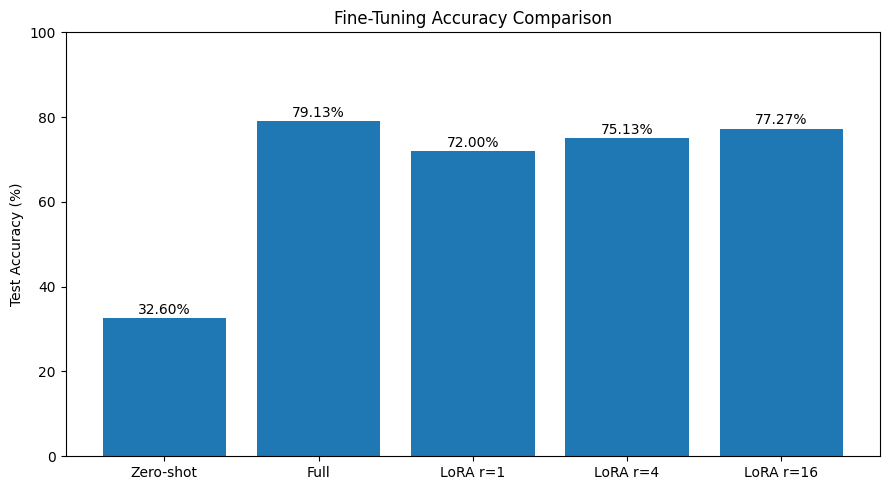

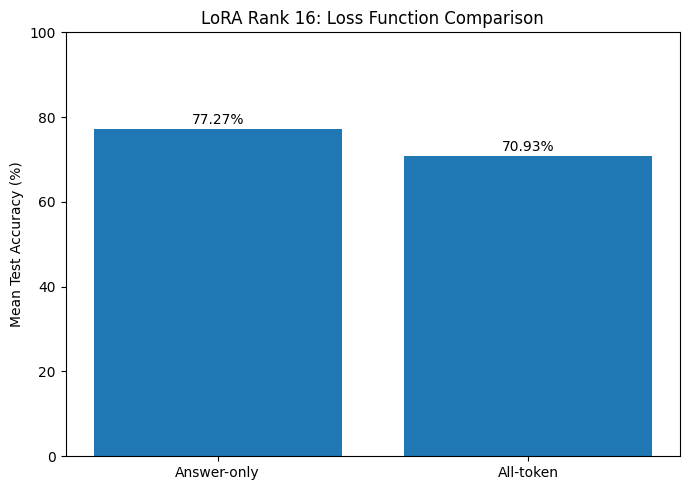

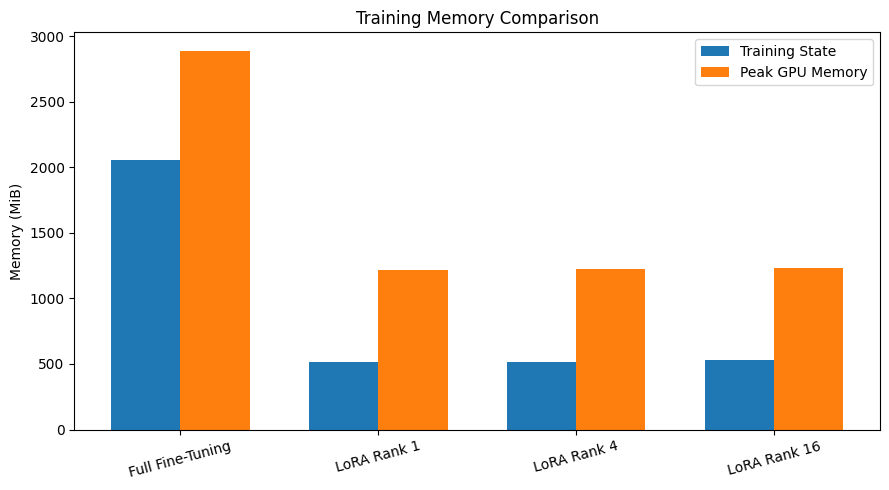

All three figures generated successfully!
['memory_comparison.png', 'accuracy_comparison.png', 'memory_results.csv', 'experiment_results.csv', 'loss_comparison.png']


In [20]:

# Step 24: Generate benchmark figures

import os
import numpy as np
import matplotlib.pyplot as plt

os.makedirs("artifacts", exist_ok=True)

# Figure 1: Accuracy comparison
methods = ["Zero-shot", "Full", "LoRA r=1", "LoRA r=4", "LoRA r=16"]
accuracies = [
    zero_shot_accuracy * 100,
    mean_accuracy * 100,
    mean_rank1 * 100,
    mean_rank4 * 100,
    mean_rank16 * 100
]

plt.figure(figsize=(9, 5))
bars = plt.bar(methods, accuracies)
plt.ylabel("Test Accuracy (%)")
plt.title("Fine-Tuning Accuracy Comparison")
plt.ylim(0, 100)

for bar, value in zip(bars, accuracies):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value + 1,
        f"{value:.2f}%",
        ha="center"
    )

plt.tight_layout()
plt.savefig("artifacts/accuracy_comparison.png", dpi=300)
plt.show()


# Figure 2: Loss comparison
plt.figure(figsize=(7, 5))

loss_methods = ["Answer-only", "All-token"]
loss_accuracy = [mean_rank16 * 100, mean_alltoken * 100]

bars = plt.bar(loss_methods, loss_accuracy)
plt.ylabel("Mean Test Accuracy (%)")
plt.title("LoRA Rank 16: Loss Function Comparison")
plt.ylim(0, 100)

for bar, value in zip(bars, loss_accuracy):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value + 1,
        f"{value:.2f}%",
        ha="center"
    )

plt.tight_layout()
plt.savefig("artifacts/loss_comparison.png", dpi=300)
plt.show()


# Figure 3: Memory comparison
x = np.arange(len(memory_df))
width = 0.35

plt.figure(figsize=(9, 5))

plt.bar(
    x - width / 2,
    memory_df["Measured State (MiB)"],
    width,
    label="Training State"
)

plt.bar(
    x + width / 2,
    memory_df["Peak GPU (MiB)"],
    width,
    label="Peak GPU Memory"
)

plt.xticks(x, memory_df["Method"], rotation=15)
plt.ylabel("Memory (MiB)")
plt.title("Training Memory Comparison")
plt.legend()

plt.tight_layout()
plt.savefig("artifacts/memory_comparison.png", dpi=300)
plt.show()

print("All three figures generated successfully!")
print(os.listdir("artifacts"))


In [21]:

# Step 25: Save all experiment results

import pandas as pd
import os

os.makedirs("artifacts", exist_ok=True)

all_results = []

experiment_groups = [
    ("Full Fine-Tuning", "Answer-only", full_results),
    ("LoRA Rank 1", "Answer-only", lora_rank1_results),
    ("LoRA Rank 4", "Answer-only", lora_rank4_results),
    ("LoRA Rank 16", "Answer-only", lora_rank16_results),
    ("LoRA Rank 16", "All-token", lora_rank16_alltoken_results)
]

for method, loss_type, results in experiment_groups:
    for seed, result in sorted(results.items()):
        all_results.append({
            "Method": method,
            "Loss": loss_type,
            "Seed": seed,
            "Accuracy": result["accuracy"],
            "Trainable_Parameters": result["trainable"],
            "Total_Parameters": result["total"],
            "Training_Time_Seconds": result["seconds"],
            "Seconds_Per_Step": result["seconds_per_step"],
            "Weight_Bytes": result["weight_bytes"],
            "Gradient_Bytes": result["grad_bytes"],
            "Optimizer_Bytes": result["optimizer_bytes"],
            "Peak_GPU_Bytes": result["peak_cuda_bytes"]
        })

results_df = pd.DataFrame(all_results)

results_df.to_csv(
    "artifacts/experiment_results.csv",
    index=False
)

memory_df.to_csv(
    "artifacts/memory_results.csv",
    index=False
)

print("Total training runs:", len(results_df))
print("Files saved successfully!")
print(os.listdir("artifacts"))

display(results_df)


Total training runs: 15
Files saved successfully!
['memory_comparison.png', 'accuracy_comparison.png', 'memory_results.csv', 'experiment_results.csv', 'loss_comparison.png']


,Method,Loss,Seed,Accuracy,Trainable_Parameters,Total_Parameters,Training_Time_Seconds,Seconds_Per_Step,Weight_Bytes,Gradient_Bytes,Optimizer_Bytes,Peak_GPU_Bytes
0,Full Fine-Tuning,Answer-only,0,0.790,134515008,134515008,34.277754,0.285648,538060032,538060032,1076120064,3026107392
1,Full Fine-Tuning,Answer-only,1,0.788,134515008,134515008,19.925101,0.166043,538060032,538060032,1076120064,3022039552
2,Full Fine-Tuning,Answer-only,2,0.796,134515008,134515008,24.639737,0.205331,538060032,538060032,1076120064,3039149056
3,LoRA Rank 1,Answer-only,0,0.722,57600,134572608,15.459163,0.128826,538290432,230400,460800,1278498304
4,LoRA Rank 1,Answer-only,1,0.716,57600,134572608,16.104721,0.134206,538290432,230400,460800,1264496128
5,LoRA Rank 1,Answer-only,2,0.722,57600,134572608,15.371362,0.128095,538290432,230400,460800,1278498304
6,LoRA Rank 4,Answer-only,0,0.764,230400,134745408,15.669053,0.130575,538981632,921600,1843200,1280694784
7,LoRA Rank 4,Answer-only,1,0.744,230400,134745408,15.795156,0.131626,538981632,921600,1843200,1266692608
8,LoRA Rank 4,Answer-only,2,0.746,230400,134745408,15.670146,0.130585,538981632,921600,1843200,1280694784
9,LoRA Rank 16,Answer-only,0,0.770,921600,135436608,15.985089,0.133209,541746432,3686400,7372800,1289910784


In [22]:

# Step 26: Generate requirements.txt

import subprocess
import sys
import os

with open("requirements.txt", "w") as file:
    subprocess.run(
        [sys.executable, "-m", "pip", "freeze"],
        stdout=file,
        check=True
    )

print("requirements.txt generated successfully!")
print("File size:", os.path.getsize("requirements.txt"), "bytes")

print("\nImportant packages:")
with open("requirements.txt", "r") as file:
    for line in file:
        if line.lower().startswith((
            "torch==",
            "transformers==",
            "peft==",
            "datasets==",
            "numpy==",
            "pandas==",
            "matplotlib==",
            "accelerate=="
        )):
            print(line.strip())


requirements.txt generated successfully!
File size: 14145 bytes

Important packages:
accelerate==1.15.0
datasets==4.8.5
matplotlib==3.10.0
numpy==2.4.6
pandas==2.2.3
peft==0.21.2
torch==2.14.1+cu130
transformers==5.22.1


In [23]:

# Step 27: Back up project files

import os
import zipfile
from google.colab import files

backup_name = "LoRA_Lab06_Project_Backup.zip"

with zipfile.ZipFile(
    backup_name,
    "w",
    zipfile.ZIP_DEFLATED
) as backup:

    for filename in [
        "lab06_starter.py",
        "requirements.txt",
        "README.md"
    ]:
        if os.path.exists(filename):
            backup.write(filename)

    for folder, _, filenames in os.walk("artifacts"):
        for filename in filenames:
            filepath = os.path.join(folder, filename)
            backup.write(filepath)

print("Backup created:", backup_name)

with zipfile.ZipFile(backup_name, "r") as backup:
    for filename in backup.namelist():
        print(filename)

files.download(backup_name)


Backup created: LoRA_Lab06_Project_Backup.zip
lab06_starter.py
requirements.txt
README.md
artifacts/memory_comparison.png
artifacts/accuracy_comparison.png
artifacts/memory_results.csv
artifacts/experiment_results.csv
artifacts/loss_comparison.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [24]:

!pip uninstall -y torchao
